In [3]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
clip_path = "C:/Users/Nora Hulth/Documents/preprocessing/test_runs/week_32/box_3/2024_08_06_16_52_08_recordings/event_data/clip_000.h5"

In [ ]:
with h5py.File(clip_path, "r") as f:
    events = f["events"][:]

In [ ]:
# If needed, sort by timestamp column (column 3)
events = events[np.argsort(events[:, 3])]

# Extract columns
x = events[:, 0]
y = events[:, 1]
p = events[:, 2]
t = events[:, 3]

# Shift time so first event starts at 0
t_rel = t - t[0]

In [201]:

# Filter:
# first 3 seconds
# y < 300
# 300 < x < 500
mask = (
    (t_rel >= 21_900_000) &
    (t_rel <= 21_910_000) &
    (y > 80) &
    (x < 400)
)

x_filt = x[mask]
y_filt = y[mask]
p_filt = p[mask]
t_filt = t_rel[mask]
t_filt = t_filt - t_filt.min()   # start at 0
t_filt = t_filt / 1e6            # convert to seconds

print("Filtered events:", len(x_filt))

# Optional recentering for display
x_plot = x_filt
sensor_height = 480  # <-- change to your sensor height

y_plot = sensor_height - y_filt

Filtered events: 9100


In [202]:
# Optional downsampling
max_points = 200_000
if len(x_plot) > max_points:
    idx = np.random.choice(len(x_plot), max_points, replace=False)
    x_plot = x_plot[idx]
    y_plot = y_plot[idx]
    t_filt = t_filt[idx]
    p_filt = p_filt[idx]

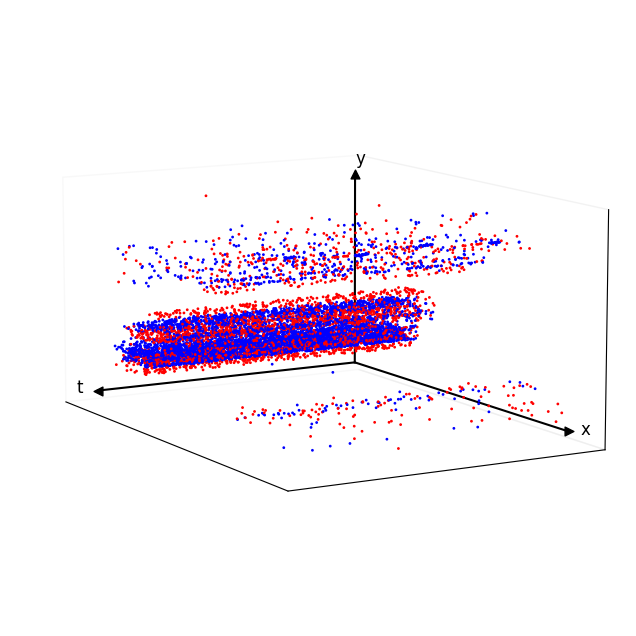

In [219]:
import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

colors = np.where(p_filt == 1, "blue", "red")

ax.scatter(
    x_plot,
    t_filt,
    y_plot,
    s=1,
    alpha=1,
    c=colors
)

# Remove ticks
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])

# Remove default labels if you want to place them manually
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_zlabel("")

# Limits
x_max = np.max(x_plot)
t_max = np.max(t_filt)
y_max = np.max(y_plot)

ax.invert_yaxis()

# Draw custom axis lines
ax.plot([0, x_max], [0, 0], [0, 0], color="black", lw=1.5)   # x-axis
ax.plot([0, 0], [0, t_max], [0, 0], color="black", lw=1.5)   # t-axis
ax.plot([0, 0], [0, 0], [0, y_max], color="black", lw=1.5)   # y-axis

# Add simple arrow tips using markers
ax.scatter([x_max], [0], [0], color="black", marker=">", s=40)
ax.scatter([0], [t_max], [0], color="black", marker="<", s=40)
ax.scatter([0], [0], [y_max], color="black", marker="^", s=40)

# Add labels near tips
ax.text(x_max * 1.05, 0, 0, "x", fontsize=12)
ax.text(0, t_max * 1.08, 0, "t", fontsize=12)
ax.text(0, 0, y_max * 1.05, "y", fontsize=12)

# Optional cleanup
ax.grid(False)
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

ax.view_init(elev=10, azim=-30)
ax.set_box_aspect((2, 1.5, 1))

plt.show()

Text(0, 418.95000000000005, 'y')

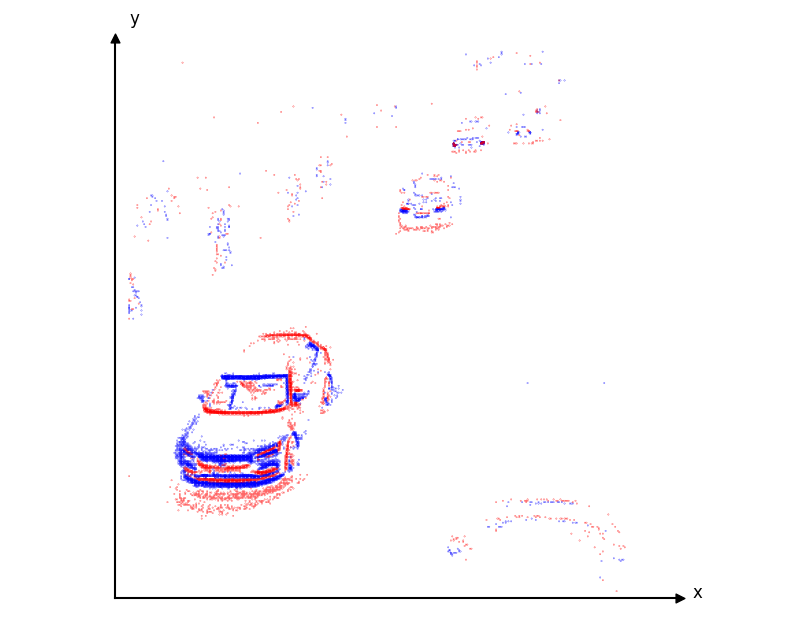

In [243]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot()
ax.scatter(x_plot, y_plot, s=0.04, color=colors)
ax.set_xticks([])
ax.set_yticks([])
plt.axis('equal')
plt.axis("off")

# Draw custom axis lines
ax.plot([-10, x_max+40], [0, 0], color="black", lw=1.5)   # x-axis
ax.plot([-10, -10], [0, y_max+10], color="black", lw=1.5)   # y-axis

# Add simple arrow tips using markers
ax.scatter([x_max+40], [0], color="black", marker=">", s=40)
ax.scatter([-10], [y_max+10], color="black", marker="^", s=40)

# Add labels near tips
ax.text((x_max+30) * 1.05, 0,  "x", fontsize=12)
ax.text(0, y_max * 1.05, "y", fontsize=12)